In [1]:
# Importing libraries

import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns

## **Data Loading**

In [2]:
# Reading data from csv and loading it into a dataframe
employee_df = pd.read_csv("/content/drive/MyDrive/Employee_Data.csv")

# Creating copy of dataframe to work with
clean_employee_df = employee_df.copy()

In [3]:
# Preview of data

clean_employee_df.head()

,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,LeaveOrNot
0,Bachelors,2017,Bangalore,3,34,Male,No,0,0
1,Bachelors,2013,Pune,1,28,Female,No,3,1
2,Bachelors,2014,New Delhi,3,38,Female,No,2,0
3,Masters,2016,Bangalore,3,27,Male,No,5,1
4,Masters,2017,Pune,3,24,Male,Yes,2,1


In [4]:
# No. of rows and columns in the dataset

rows, columns = clean_employee_df.shape

print(f"No. of rows: {rows}")
print(f"No. of columns: {columns}")

No. of rows: 4653
No. of columns: 9


## **Business Questions**

**Employee demographics**

1) What is the most common highest qualification among employees?
2) What is the gender split?
3) How many employees are in each age group, and what is the average age?
4) Which city has the most employees?

**Workforce structure**

5) How are employees distributed across payment tiers?
6) How much experience do employees have in their current domain? Are most entry-level or experienced?
7) Is payment tier related to experience in the domain?
8) How has the number of new joiners changed by year?

**Resignation Analysis**

9) What is the overall resignation rate?
10) Which groups resign at noticeably higher or lower rates (by education, city, tier, gender, age group, experience level)?
11) Do resignation patterns change by joining year?
12) Are employees who have been benched more likely to resign?

**Benching Analysis**

13) What percentage of employees have been benched at least once?
14) Does the benched share differ by payment tier?
15) Does the benched share differ by experience level?
16) Are other groups (gender, city, education, age) benched more or less often?


## **Data Exploration**

In [5]:
# Information on columns

clean_employee_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4653 entries, 0 to 4652
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Education                  4653 non-null   object
 1   JoiningYear                4653 non-null   int64 
 2   City                       4653 non-null   object
 3   PaymentTier                4653 non-null   int64 
 4   Age                        4653 non-null   int64 
 5   Gender                     4653 non-null   object
 6   EverBenched                4653 non-null   object
 7   ExperienceInCurrentDomain  4653 non-null   int64 
 8   LeaveOrNot                 4653 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 327.3+ KB


**Renaming columns**

In [6]:
# Renaming columns

new_column_names = {
    'Education':'education',
    'JoiningYear':'joining_year',
    'City':'city',
    'PaymentTier':'payment_tier',
    'Age':'age',
    'Gender':'gender',
    'EverBenched':'benched_status',
    'ExperienceInCurrentDomain':'experience_in_current_domain',
    'LeaveOrNot':'employee_status'
}

clean_employee_df = clean_employee_df.rename(columns=new_column_names)

In [7]:
clean_employee_df.head()

,education,joining_year,city,payment_tier,age,gender,benched_status,experience_in_current_domain,employee_status
0,Bachelors,2017,Bangalore,3,34,Male,No,0,0
1,Bachelors,2013,Pune,1,28,Female,No,3,1
2,Bachelors,2014,New Delhi,3,38,Female,No,2,0
3,Masters,2016,Bangalore,3,27,Male,No,5,1
4,Masters,2017,Pune,3,24,Male,Yes,2,1


**Column definitions**

1) education - Highest level of formal education obtained by the employee
2) joining_year - Year of joining the company
3) city - Job location
4) payment_tier - Payment tier (1-3). 3 means better pay.
5) age - Age of the employee
6) gender - Gender of the employee
7) benched_status - Was the employee ever benched or not
8) experience_in_current_domain - Work experience in the current domain
9) employee_status - Whether the employee left the company or not

In [8]:
clean_employee_df.columns

Index(['education', 'joining_year', 'city', 'payment_tier', 'age', 'gender',
       'benched_status', 'experience_in_current_domain', 'employee_status'],
      dtype='object')

**Statistical analysis of columns**

In [9]:
# Statistical analysis of all columns

clean_employee_df.describe(include="all")

,education,joining_year,city,payment_tier,age,gender,benched_status,experience_in_current_domain,employee_status
count,4653,4653.000000,4653,4653.000000,4653.000000,4653,4653,4653.000000,4653.000000
unique,3,NaN,3,NaN,NaN,2,2,NaN,NaN
top,Bachelors,NaN,Bangalore,NaN,NaN,Male,No,NaN,NaN
freq,3601,NaN,2228,NaN,NaN,2778,4175,NaN,NaN
mean,NaN,2015.062970,NaN,2.698259,29.393295,NaN,NaN,2.905652,0.343864
std,NaN,1.863377,NaN,0.561435,4.826087,NaN,NaN,1.558240,0.475047
min,NaN,2012.000000,NaN,1.000000,22.000000,NaN,NaN,0.000000,0.000000
25%,NaN,2013.000000,NaN,3.000000,26.000000,NaN,NaN,2.000000,0.000000
50%,NaN,2015.000000,NaN,3.000000,28.000000,NaN,NaN,3.000000,0.000000
75%,NaN,2017.000000,NaN,3.000000,32.000000,NaN,NaN,4.000000,1.000000


**Missing values**

In [10]:
# Missing values

missing_values_df = clean_employee_df.isnull().sum().to_frame("missing_count")

missing_values_df["missing_percentage"] = ( missing_values_df["missing_count"] / len(clean_employee_df) * 100 ).round(2)

missing_values_df

,missing_count,missing_percentage
education,0,0.0
joining_year,0,0.0
city,0,0.0
payment_tier,0,0.0
age,0,0.0
gender,0,0.0
benched_status,0,0.0
experience_in_current_domain,0,0.0
employee_status,0,0.0


**Duplicate records**

In [11]:
# Duplicate records

duplicate_records_count = clean_employee_df.duplicated().sum()

duplicate_records_percentage = duplicate_records_count / len(clean_employee_df) * 100

print("No. of duplicate records:", duplicate_records_count)
print(f"Percentage of duplicate records: {duplicate_records_percentage:.2f}%")

No. of duplicate records: 1889
Percentage of duplicate records: 40.60%


In [12]:
clean_employee_df[clean_employee_df.duplicated()]

,education,joining_year,city,payment_tier,age,gender,benched_status,experience_in_current_domain,employee_status
111,Bachelors,2017,Pune,2,27,Female,No,5,1
130,Bachelors,2017,Bangalore,3,26,Female,No,4,0
138,Bachelors,2017,New Delhi,3,28,Male,No,2,0
160,Bachelors,2014,Bangalore,3,28,Female,No,3,0
167,Bachelors,2014,Bangalore,3,25,Male,No,3,0
...,...,...,...,...,...,...,...,...,...
4640,Bachelors,2015,Bangalore,3,35,Male,No,0,0
4642,Bachelors,2012,Bangalore,3,36,Female,No,4,0
4646,Bachelors,2013,Bangalore,3,25,Female,No,3,0
4648,Bachelors,2013,Bangalore,3,26,Female,No,4,0


**Note**

There are 1889 duplicated records. But since there is no unique ID column and duplicate rows can represent different employees, duplicates are not removed.

**Categorical columns**

In [13]:
# Categorical columns

categorical_columns = ["education","city","payment_tier","gender","benched_status","employee_status"]

for column in categorical_columns:
  print(column.capitalize())
  print("----------------------------------")
  display(clean_employee_df[column].value_counts().reset_index().sort_values(column))
  print("\n")

Education
----------------------------------


,education,count
0,Bachelors,3601
1,Masters,873
2,PHD,179




City
----------------------------------


,city,count
0,Bangalore,2228
2,New Delhi,1157
1,Pune,1268




Payment_tier
----------------------------------


...

,gender,count
1,Female,1875
0,Male,2778




Benched_status
----------------------------------


,benched_status,count
0,No,4175
1,Yes,478




Employee_status
----------------------------------


,employee_status,count
0,0,3053
1,1,1600


**Numerical Columns**

In [14]:
# Numerical columns

numerical_columns = ["age","experience_in_current_domain"]

numerical_column_statistics = clean_employee_df.describe()[numerical_columns]

numerical_column_statistics.loc[["count","min","max","mean"]]

,age,experience_in_current_domain
count,4653.000000,4653.000000
min,22.000000,0.000000
max,41.000000,7.000000
mean,29.393295,2.905652


**Date Columns**

In [15]:
# Date related columns

date_columns = ["joining_year"]

date_column_statistics = clean_employee_df.describe()[date_columns]

date_column_statistics.loc[["count","min","max"]]

,joining_year
count,4653.0
min,2012.0
max,2018.0


In [16]:
# Checking for missing years

years_values = clean_employee_df["joining_year"].unique()

minimum_year = clean_employee_df["joining_year"].min()
maximum_year = clean_employee_df["joining_year"].max()

year_range = pd.Series(range(minimum_year,maximum_year+1))

missing_years = year_range[~year_range.isin(years_values)]

if missing_years.empty:
  print("No missing years")
else:
  print(f"Missing years: {missing_years.values}")

No missing years


In [17]:
clean_employee_df.head()

,education,joining_year,city,payment_tier,age,gender,benched_status,experience_in_current_domain,employee_status
0,Bachelors,2017,Bangalore,3,34,Male,No,0,0
1,Bachelors,2013,Pune,1,28,Female,No,3,1
2,Bachelors,2014,New Delhi,3,38,Female,No,2,0
3,Masters,2016,Bangalore,3,27,Male,No,5,1
4,Masters,2017,Pune,3,24,Male,Yes,2,1


## **Data Cleaning**

In [18]:
# Removing duplicates
# clean_employee_df = clean_employee_df.drop_duplicates()

In [19]:
# Replacing values in "benched_status" column
clean_employee_df["benched_status"] = clean_employee_df["benched_status"].str.lower().map({"no": "Never benched","yes": "Benched"})

In [20]:
# Replacing values in "employee_status" column
clean_employee_df["employee_status"] = clean_employee_df["employee_status"].map({0: "Active", 1: "Resigned"})

In [21]:
# Replacing values in "payment_tier" column and converting into string
clean_employee_df["payment_tier"] = "Tier " + clean_employee_df["payment_tier"].astype(str)

In [22]:
# Adding new columns for age group and experience level
clean_employee_df["age_group"] = pd.cut(clean_employee_df["age"],bins=[21,25,30,35,40,50],labels=["21 - 25","26 - 30","31 - 35","36 - 40","41+"],include_lowest=True)
clean_employee_df["experience_level"] = pd.cut(clean_employee_df["experience_in_current_domain"],bins=[0,1,4,7],labels=["Entry (0-1 years)","Intermediate (2-4 years)","Senior (5-7 years)"],include_lowest=True)

In [23]:
clean_employee_df.head()

,education,joining_year,city,payment_tier,age,gender,benched_status,experience_in_current_domain,employee_status,age_group,experience_level
0,Bachelors,2017,Bangalore,Tier 3,34,Male,Never benched,0,Active,31 - 35,Entry (0-1 years)
1,Bachelors,2013,Pune,Tier 1,28,Female,Never benched,3,Resigned,26 - 30,Intermediate (2-4 years)
2,Bachelors,2014,New Delhi,Tier 3,38,Female,Never benched,2,Active,36 - 40,Intermediate (2-4 years)
3,Masters,2016,Bangalore,Tier 3,27,Male,Never benched,5,Resigned,26 - 30,Senior (5-7 years)
4,Masters,2017,Pune,Tier 3,24,Male,Benched,2,Resigned,21 - 25,Intermediate (2-4 years)


## **Analysis**

In [24]:
# Function for value counts of categorical columns

def fn_value_count(df,column):
  value_count = df[column].value_counts()
  return value_count

# Function for data  labels

def fn_data_label(graph,format="%g"):
  for container in graph.containers:
    graph.bar_label(container,padding=3,fmt=format)

**Employee demographics**

1) What is the most common highest qualification among employees?
2) What is the gender split?
3) How many employees are in each age group, and what is the average age?
4) Which city has the most employees?

1) What is the most common highest qualification among employees?

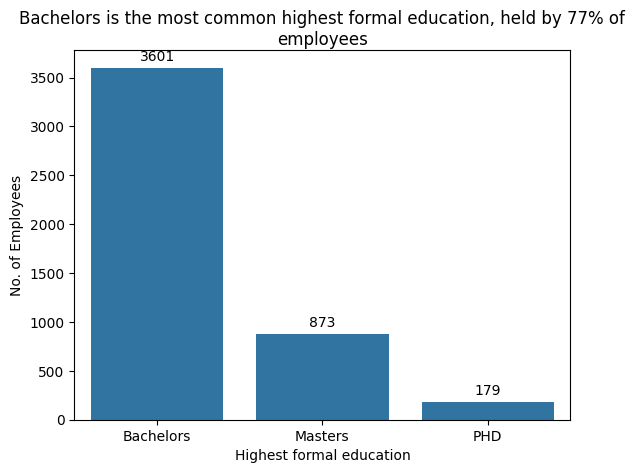

In [25]:
# Employee distribution by education qualification

employees_by_education= fn_value_count(clean_employee_df,"education")

most_common_education = employees_by_education.idxmax()

most_common_education_percentage = (employees_by_education.max() / len(clean_employee_df) * 100)

graph = sns.barplot(x=employees_by_education.index,y=employees_by_education.values)

fn_data_label(graph)

plt.xlabel("Highest formal education")
plt.ylabel("No. of Employees")
plt.title(f"{most_common_education} is the most common highest formal education, held by {most_common_education_percentage:.0f}% of employees",size=12,wrap=True)
plt.show()

2) What is the gender split?

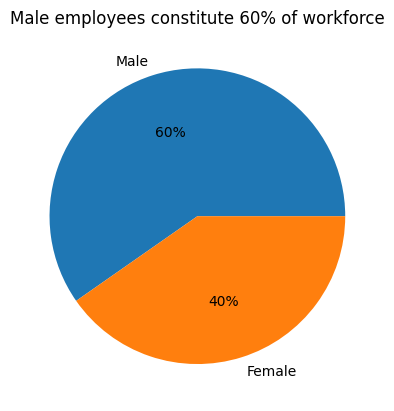

In [26]:
# Employee distribution by gender

employees_by_gender = fn_value_count(clean_employee_df,"gender")

highest_count_gender = employees_by_gender.idxmax()

highest_count_gender_percentage = (employees_by_gender.max() / len(clean_employee_df) * 100)

plt.pie(x=employees_by_gender.values,labels=employees_by_gender.index,autopct='%1.0f%%')
plt.title(f"{highest_count_gender} employees constitute {highest_count_gender_percentage:.0f}% of workforce",size=12)
plt.show()

3) How many employees are in each age group, and what is the average age?

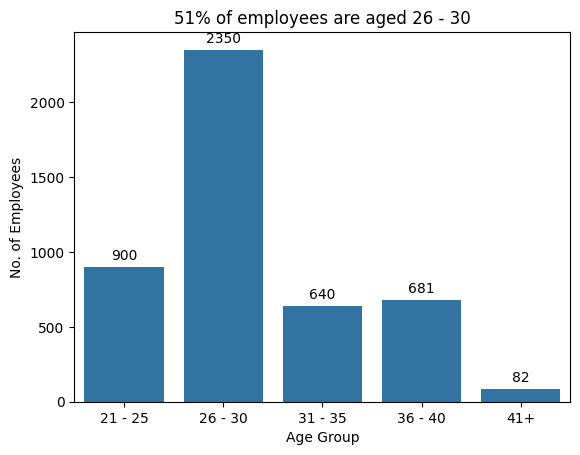

In [27]:
# Employee distribution by age group

employees_by_age_group = fn_value_count(clean_employee_df,"age_group").sort_index()

most_common_age_group = employees_by_age_group.idxmax()

most_common_age_group_percentage = (employees_by_age_group.max() / len(clean_employee_df) * 100)

graph = sns.barplot(x=employees_by_age_group.index,y=employees_by_age_group.values)

fn_data_label(graph)

plt.xlabel("Age Group")
plt.ylabel("No. of Employees")
plt.title(f"{most_common_age_group_percentage:.0f}% of employees are aged {most_common_age_group}",size=12)
plt.show()

In [28]:
# Average age of employees
average_age = clean_employee_df["age"].mean()

print(f"Average age of employees is {average_age:.0f}")

Average age of employees is 29


In [29]:
clean_employee_df.describe()["age"]

,age
count,4653.000000
mean,29.393295
std,4.826087
min,22.000000
25%,26.000000
50%,28.000000
75%,32.000000
max,41.000000


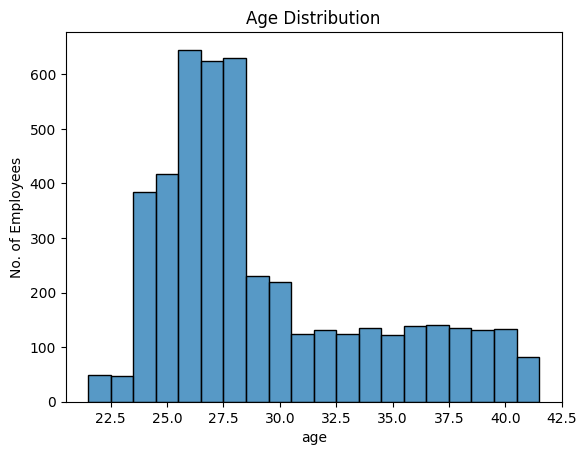

In [30]:
# Age distribution

sns.histplot(clean_employee_df,x="age",discrete=True)
plt.ylabel("No. of Employees")
plt.title("Age Distribution")
plt.show()

In [31]:
(clean_employee_df['age'].isin([26,27,28]).sum() / len(clean_employee_df) * 100).round(0).item()

41.0

**Note**

The workforce comprises mostly young people, aged under 30, with 41% of employees aged between 26 and 28.

4) Which city has the most employees?

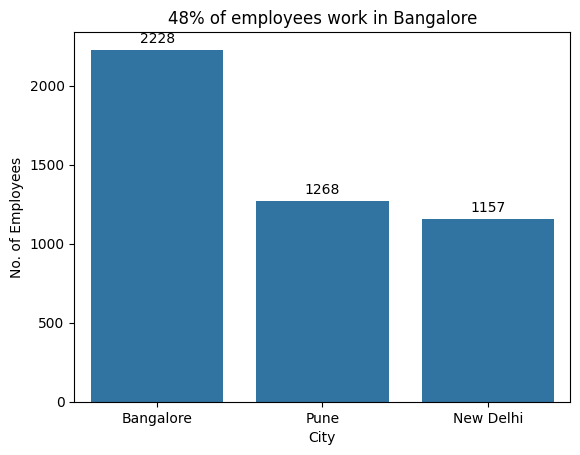

In [32]:
# Employee distribution by appointed city

employees_by_city = fn_value_count(clean_employee_df,"city")

most_employees_city = employees_by_city.idxmax()

most_employees_city_percentage = (employees_by_city.max() / len(clean_employee_df) * 100)

graph = sns.barplot(x=employees_by_city.index,y=employees_by_city.values)

fn_data_label(graph)

plt.xlabel("City")
plt.ylabel("No. of Employees")
plt.title(f"{most_employees_city_percentage:.0f}% of employees work in {most_employees_city}",size=12)
plt.show()

**Workforce structure**

5) How are employees distributed across payment tiers?
6) How much experience do employees have in their current domain? Are most entry-level or experienced?
7) Is payment tier related to experience in the domain?
8) How has the number of new joiners changed by year?

5) How are employees distributed across payment tiers?

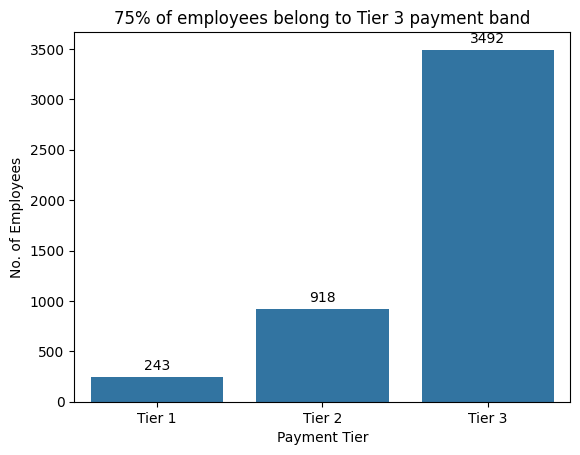

In [33]:
# Employee distribution by payment tier

employees_by_payment_tier = fn_value_count(clean_employee_df,"payment_tier").sort_index()

most_employees_payment_tier = employees_by_payment_tier.idxmax()

most_employees_payment_tier_percentage = (employees_by_payment_tier.max() / len(clean_employee_df) * 100)

graph = sns.barplot(x=employees_by_payment_tier.index,y=employees_by_payment_tier.values)

fn_data_label(graph)

plt.xlabel("Payment Tier")
plt.ylabel("No. of Employees")
plt.title(f"{most_employees_payment_tier_percentage:.0f}% of employees belong to {most_employees_payment_tier} payment band",size=12)
plt.show()

6) How much experience do employees have in their current domain? Are most entry-level or experienced?

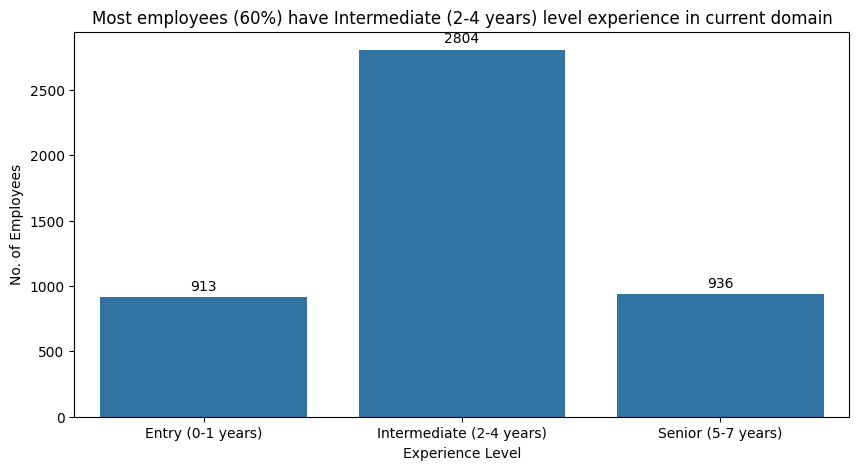

In [34]:
# Employee distribution by experience level

employees_by_experience_level = fn_value_count(clean_employee_df,"experience_level").sort_index()

most_employees_experience_level = employees_by_experience_level.idxmax()

most_employees_experience_level_percentage = (employees_by_experience_level.max() / len(clean_employee_df) * 100)

plt.figure(figsize=(10,5))

graph = sns.barplot(x=employees_by_experience_level.index,y=employees_by_experience_level.values)

fn_data_label(graph)

plt.xlabel("Experience Level")
plt.ylabel("No. of Employees")
plt.title(f"Most employees ({most_employees_experience_level_percentage:.0f}%) have {most_employees_experience_level} level experience in current domain",size=12)
plt.show()

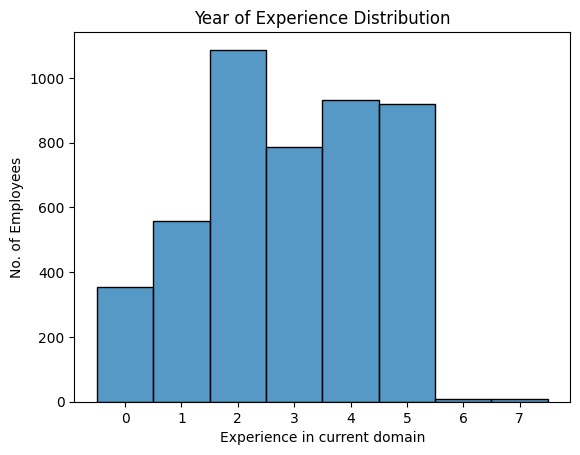

In [35]:
# Experience distribution

sns.histplot(clean_employee_df,x="experience_in_current_domain",discrete=True)
plt.xlabel("Experience in current domain")
plt.ylabel("No. of Employees")
plt.title("Year of Experience Distribution")
plt.show()

In [36]:
clean_employee_df.describe()["experience_in_current_domain"]

,experience_in_current_domain
count,4653.000000
mean,2.905652
std,1.558240
min,0.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,7.000000


In [37]:
len(clean_employee_df[clean_employee_df["experience_in_current_domain"].isin([2,3,4,5])]) / len(clean_employee_df) * 100

80.01289490651193

In [38]:
len(clean_employee_df[clean_employee_df["experience_in_current_domain"] > 5]) / len(clean_employee_df) * 100

0.3653556845046207

**Note**

80% of employees have 2 to 5 years of experience in current domain.
Less than 1% of employees have more than 5 year of experience.

7) Is payment tier related to experience in the domain?

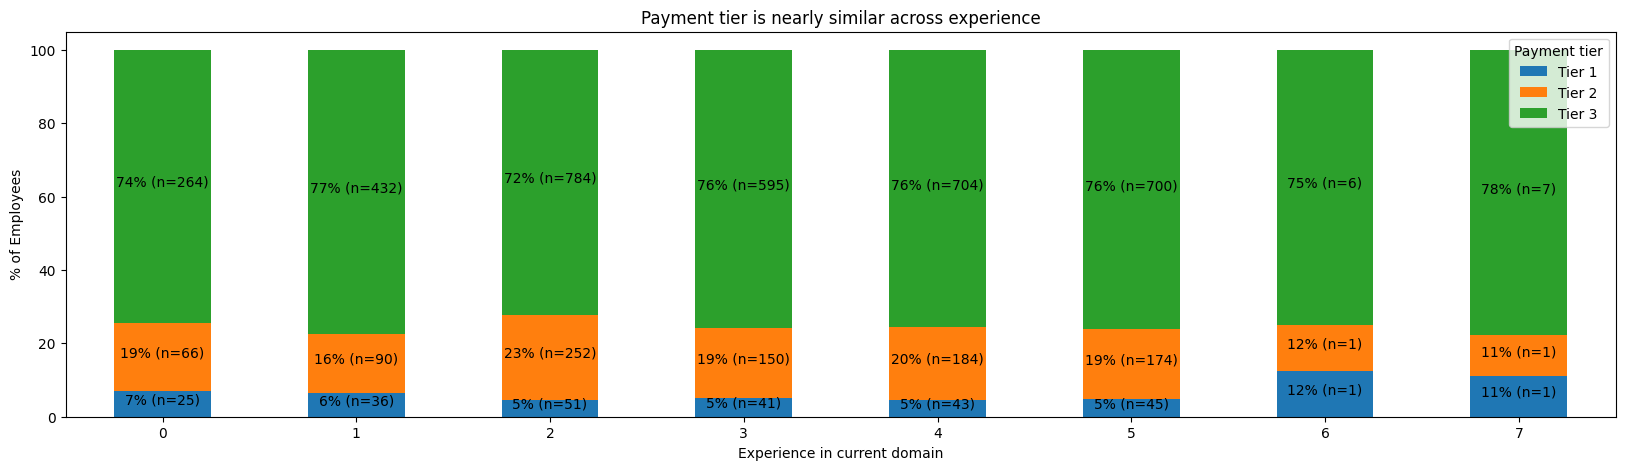

In [39]:
# Experience in current domain vs payment tier

payment_experience_count = pd.crosstab(index=clean_employee_df["experience_in_current_domain"],columns=clean_employee_df["payment_tier"])

payment_experience_percentage = (pd.crosstab(index=clean_employee_df["experience_in_current_domain"],columns=clean_employee_df["payment_tier"],normalize="index") * 100)

graph = payment_experience_percentage.plot.bar(stacked=True,figsize=(20,5),rot=0)

for tier,container in zip(payment_experience_percentage.columns,graph.containers):
  labels = [f"{percentage:.0f}% (n={cnt})" for percentage, cnt in zip(payment_experience_percentage[tier],payment_experience_count[tier])]
  graph.bar_label(container=container,padding=3,labels=labels,label_type='center')

plt.xlabel("Experience in current domain")
plt.ylabel("% of Employees")
plt.legend(title="Payment tier")
plt.title("Payment tier is nearly similar across experience")
plt.show()

8) How has the number of new joiners changed by year?

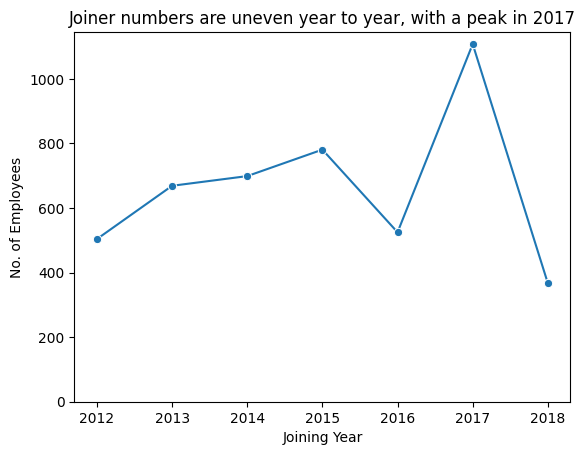

In [40]:
# Employee distribution by joining year

employees_by_joining_year =fn_value_count(clean_employee_df,"joining_year").sort_index()

sns.lineplot(employees_by_joining_year,marker="o")

plt.xlabel("Joining Year")
plt.ylabel("No. of Employees")
plt.ylim(0, None)
plt.title("Joiner numbers are uneven year to year, with a peak in 2017")
plt.show()

Are age and experience related?

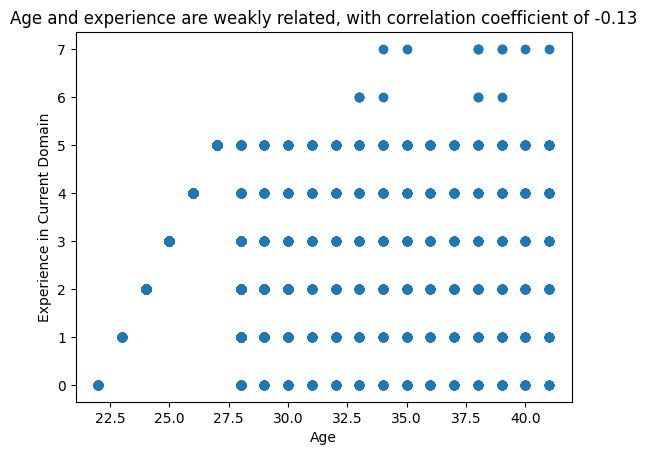

In [63]:
# Age vs experience

corr_coefficient = clean_employee_df["age"].corr(clean_employee_df["experience_in_current_domain"])

plt.scatter(x=clean_employee_df["age"],y=clean_employee_df["experience_in_current_domain"])
plt.xlabel("Age")
plt.ylabel("Experience in Current Domain")
plt.title(f"Age and experience are weakly related, with correlation coefficient of {corr_coefficient:.2f}")
plt.show()

**Resignation Analysis**

9) What is the overall resignation rate?
10) Which groups resign at noticeably higher or lower rates (by education, city, tier, gender, age group, experience level)?
11) Do resignation patterns change by joining year?
12) Are employees who have been benched more likely to resign?

9) What is the overall resignation rate?

34%


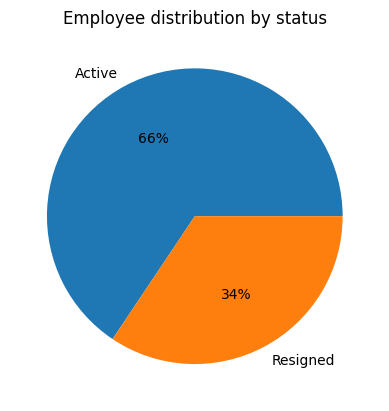

In [42]:
# Resignation rate = (resigned employees / total employees) * 100

resignation_rate = (clean_employee_df["employee_status"]=="Resigned").sum().item() / len(clean_employee_df) * 100

print(f"{resignation_rate:.0f}%")

employee_status_count = fn_value_count(clean_employee_df,"employee_status")

plt.pie(x=employee_status_count.values,labels=employee_status_count.index,autopct="%1.0f%%")
plt.title("Employee distribution by status")
plt.show()

10) Which groups resign at noticeably higher or lower rates (by education, city, tier, gender, age group, experience level)?

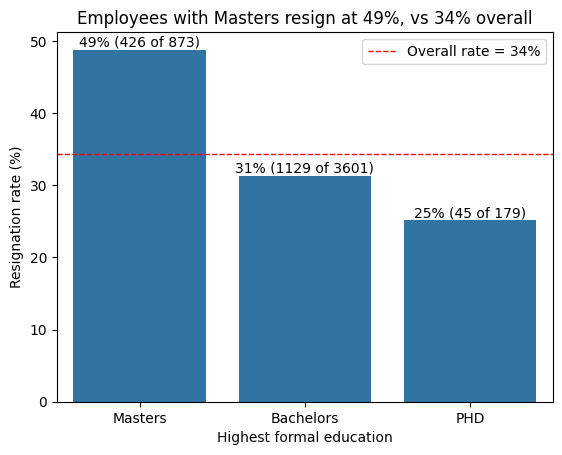

In [43]:
# Resignation rate by education

resignations_by_education = (pd.crosstab(index=clean_employee_df['education'],columns=clean_employee_df['employee_status'],margins=True,margins_name="Total")).drop(labels="Total")

resignations_by_education["Rate"] = (resignations_by_education["Resigned"] / resignations_by_education["Total"]) * 100

resignations_by_education = resignations_by_education.sort_values(by="Rate",ascending=False)

education_with_highest_rate, highest_rate_by_education = (resignations_by_education["Rate"].idxmax(), resignations_by_education["Rate"].max())

graph = sns.barplot(data=resignations_by_education,x=resignations_by_education.index,y=resignations_by_education["Rate"])

for container in graph.containers:
  labels = [f"{resignations_by_education["Rate"].loc[education]:.0f}% ({resignations_by_education["Resigned"].loc[education]} of {resignations_by_education["Total"].loc[education]})" for education in resignations_by_education.index]
  graph.bar_label(container,labels=labels)

plt.xlabel("Highest formal education")
plt.ylabel("Resignation rate (%)")
plt.title(f"Employees with {education_with_highest_rate} resign at {highest_rate_by_education:.0f}%, vs {resignation_rate:.0f}% overall")
graph.axhline(y=resignation_rate, color='red', linestyle='--', linewidth=1.0, label=f"Overall rate = {resignation_rate:.0f}%")
graph.legend()
plt.show()

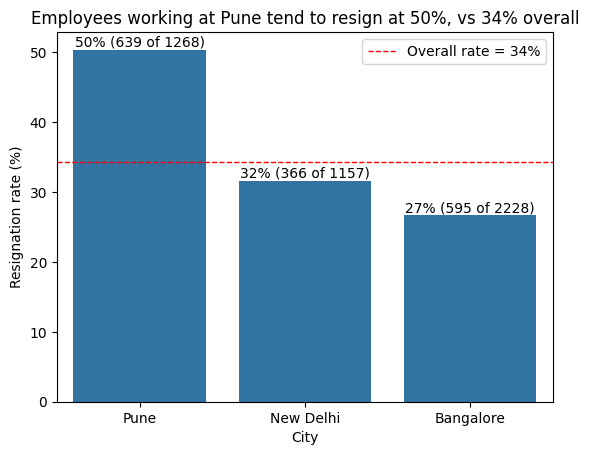

In [44]:
# Resignation rate by city

resignations_by_city = (pd.crosstab(index=clean_employee_df['city'],columns=clean_employee_df['employee_status'],margins=True,margins_name="Total")).drop(labels="Total")

resignations_by_city["Rate"] = (resignations_by_city["Resigned"] / resignations_by_city["Total"]) * 100

resignations_by_city = resignations_by_city.sort_values(by="Rate",ascending=False)

city_with_highest_rate, highest_rate_by_city = (resignations_by_city["Rate"].idxmax(), resignations_by_city["Rate"].max())

graph = sns.barplot(data=resignations_by_city,x=resignations_by_city.index,y=resignations_by_city["Rate"])

for container in graph.containers:
  labels = [f"{resignations_by_city["Rate"].loc[city]:.0f}% ({resignations_by_city["Resigned"].loc[city]} of {resignations_by_city["Total"].loc[city]})" for city in resignations_by_city.index]
  graph.bar_label(container,labels=labels)


plt.xlabel("City")
plt.ylabel("Resignation rate (%)")
plt.title(f"Employees working at {city_with_highest_rate} tend to resign at {highest_rate_by_city:.0f}%, vs {resignation_rate:.0f}% overall")
graph.axhline(y=resignation_rate, color='red', linestyle='--', linewidth=1.0, label=f"Overall rate = {resignation_rate:.0f}%")
graph.legend()
plt.show()

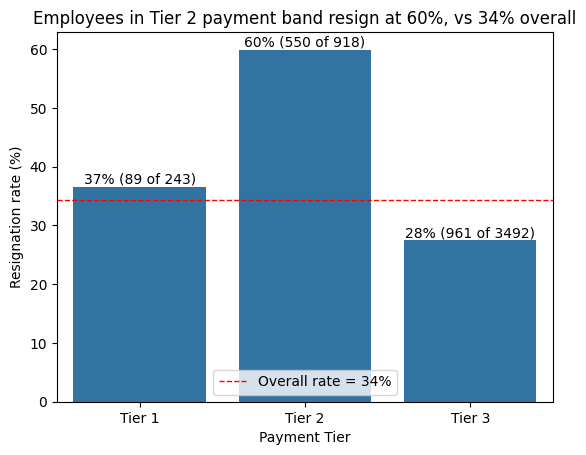

In [45]:
# Resignation rate by payment tier

resignations_by_payment_tier = (pd.crosstab(index=clean_employee_df['payment_tier'],columns=clean_employee_df['employee_status'],margins=True,margins_name="Total")).drop(labels="Total")

resignations_by_payment_tier["Rate"] = (resignations_by_payment_tier["Resigned"] / resignations_by_payment_tier["Total"]) * 100

resignations_by_payment_tier = resignations_by_payment_tier.sort_index(ascending=True)

payment_tier_with_highest_rate, highest_rate_by_payment_tier = (resignations_by_payment_tier["Rate"].idxmax(), resignations_by_payment_tier["Rate"].max())

graph = sns.barplot(data=resignations_by_payment_tier,x=resignations_by_payment_tier.index,y=resignations_by_payment_tier["Rate"])

for container in graph.containers:
  labels = [f"{resignations_by_payment_tier["Rate"].loc[tier]:.0f}% ({resignations_by_payment_tier["Resigned"].loc[tier]} of {resignations_by_payment_tier["Total"].loc[tier]})" for tier in resignations_by_payment_tier.index]
  graph.bar_label(container,labels=labels)


plt.xlabel("Payment Tier")
plt.ylabel("Resignation rate (%)")
plt.title(f"Employees in {payment_tier_with_highest_rate} payment band resign at {highest_rate_by_payment_tier:.0f}%, vs {resignation_rate:.0f}% overall")
graph.axhline(y=resignation_rate, color='red', linestyle='--', linewidth=1.0, label=f"Overall rate = {resignation_rate:.0f}%")
graph.legend()
plt.show()

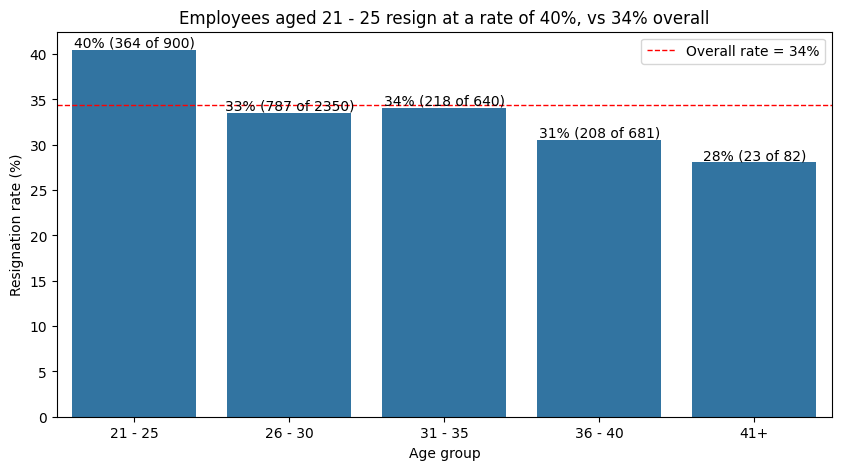

In [46]:
# Resignation rate by age group

resignations_by_age_group = (pd.crosstab(index=clean_employee_df['age_group'],columns=clean_employee_df['employee_status'],margins=True,margins_name="Total")).drop(labels="Total")

resignations_by_age_group["Rate"] = (resignations_by_age_group["Resigned"] / resignations_by_age_group["Total"]) * 100

resignations_by_age_group = resignations_by_age_group.sort_index(ascending=True)

age_group_with_highest_rate, highest_rate_by_age_group = (resignations_by_age_group["Rate"].idxmax(), resignations_by_age_group["Rate"].max())

plt.figure(figsize=(10,5))

graph = sns.barplot(data=resignations_by_age_group,x=resignations_by_age_group.index,y=resignations_by_age_group["Rate"])

for container in graph.containers:
  labels = [f"{resignations_by_age_group["Rate"].loc[age_group]:.0f}% ({resignations_by_age_group["Resigned"].loc[age_group]} of {resignations_by_age_group["Total"].loc[age_group]})" for age_group in resignations_by_age_group.index]
  graph.bar_label(container,labels=labels)


plt.xlabel("Age group")
plt.ylabel("Resignation rate (%)")
plt.title(f"Employees aged {age_group_with_highest_rate} resign at a rate of {highest_rate_by_age_group:.0f}%, vs {resignation_rate:.0f}% overall")
graph.axhline(y=resignation_rate, color='red', linestyle='--', linewidth=1.0, label=f"Overall rate = {resignation_rate:.0f}%")
graph.legend()
plt.show()

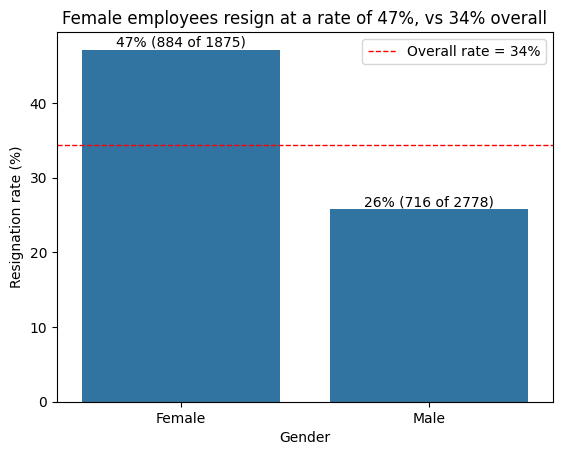

In [47]:
# Resignation rate by gender

resignations_by_gender = (pd.crosstab(index=clean_employee_df['gender'],columns=clean_employee_df['employee_status'],margins=True,margins_name="Total")).drop(labels="Total")

resignations_by_gender["Rate"] = (resignations_by_gender["Resigned"] / resignations_by_gender["Total"]) * 100

resignations_by_gender = resignations_by_gender.sort_values(by="Rate",ascending=False)

gender_with_highest_rate, highest_rate_by_gender = (resignations_by_gender["Rate"].idxmax(), resignations_by_gender["Rate"].max())

graph = sns.barplot(data=resignations_by_gender,x=resignations_by_gender.index,y=resignations_by_gender["Rate"])

for container in graph.containers:
  labels = [f"{resignations_by_gender["Rate"].loc[gender]:.0f}% ({resignations_by_gender["Resigned"].loc[gender]} of {resignations_by_gender["Total"].loc[gender]})" for gender in resignations_by_gender.index]
  graph.bar_label(container,labels=labels)

plt.xlabel("Gender")
plt.ylabel("Resignation rate (%)")
plt.title(f"{gender_with_highest_rate} employees resign at a rate of {highest_rate_by_gender:.0f}%, vs {resignation_rate:.0f}% overall")
graph.axhline(y=resignation_rate, color='red', linestyle='--', linewidth=1.0, label=f"Overall rate = {resignation_rate:.0f}%")
graph.legend()
plt.show()

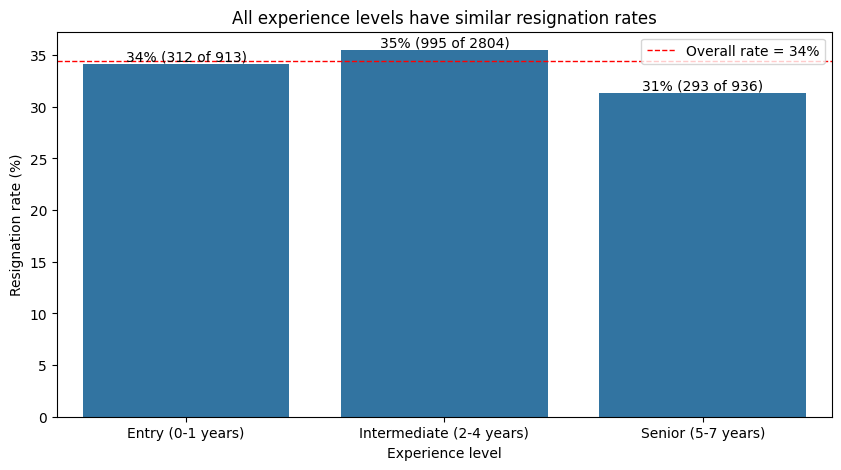

In [48]:
# Resignation rate by experience level

resignations_by_experience_level = (pd.crosstab(index=clean_employee_df['experience_level'],columns=clean_employee_df['employee_status'],margins=True,margins_name="Total")).drop(labels="Total")

resignations_by_experience_level["Rate"] = (resignations_by_experience_level["Resigned"] / resignations_by_experience_level["Total"]) * 100

resignations_by_experience_level = resignations_by_experience_level.sort_index(ascending=True)

experience_level_with_highest_rate, highest_rate_by_experience_level = (resignations_by_experience_level["Rate"].idxmax(), resignations_by_experience_level["Rate"].max())

plt.figure(figsize=(10,5))

graph = sns.barplot(data=resignations_by_experience_level,x=resignations_by_experience_level.index,y=resignations_by_experience_level["Rate"])

for container in graph.containers:
  labels = [f"{resignations_by_experience_level["Rate"].loc[level]:.0f}% ({resignations_by_experience_level["Resigned"].loc[level]} of {resignations_by_experience_level["Total"].loc[level]})" for level in resignations_by_experience_level.index]
  graph.bar_label(container,labels=labels)

plt.xlabel("Experience level")
plt.ylabel("Resignation rate (%)")
plt.title(f"All experience levels have similar resignation rates")
graph.axhline(y=resignation_rate, color='red', linestyle='--', linewidth=1.0, label=f"Overall rate = {resignation_rate:.0f}%")
graph.legend()
plt.show()

11) Do resignation patterns change by joining year?

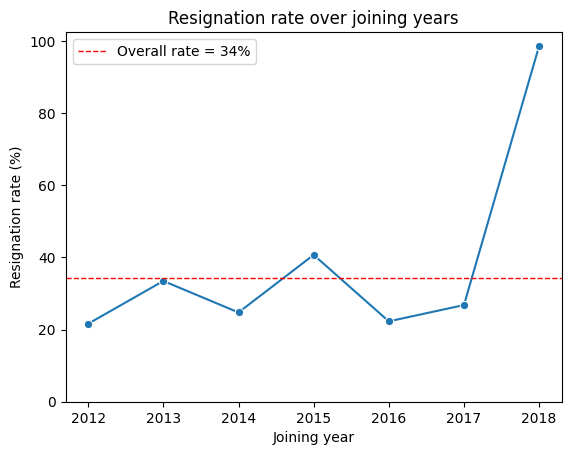

In [49]:
# Resignation rate by joining year

resignation_rate_by_joining_year = (pd.crosstab(index=clean_employee_df['joining_year'],columns=clean_employee_df['employee_status'],normalize="index") * 100)["Resigned"]

joining_year_with_highest_rate, highest_rate_by_joining_year = (resignation_rate_by_joining_year.idxmax(), resignation_rate_by_joining_year.max())

graph = sns.lineplot(resignation_rate_by_joining_year,marker="o")

# for container in graph.containers:
#   graph.lines()

plt.xlabel("Joining year")
plt.ylabel("Resignation rate (%)")
plt.title(f"Resignation rate over joining years")
plt.ylim(0,None)
graph.axhline(y=resignation_rate, color='red', linestyle='--', linewidth=1.0, label=f"Overall rate = {resignation_rate:.0f}%")
graph.legend()
plt.show()

12) Are employees who have been benched more likely to resign?

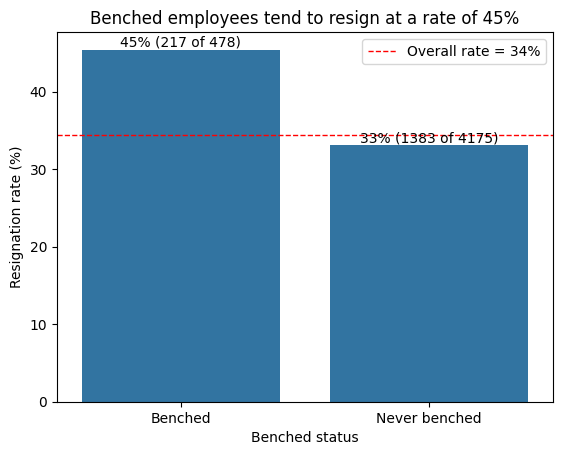

In [50]:
# Benched status vs resignation

resignations_by_benched_status = (pd.crosstab(index=clean_employee_df['benched_status'],columns=clean_employee_df['employee_status'],margins=True,margins_name="Total")).drop(labels="Total")

resignations_by_benched_status["Rate"] = (resignations_by_benched_status["Resigned"] / resignations_by_benched_status["Total"]) * 100

resignations_by_benched_status = resignations_by_benched_status.sort_values(by="Rate",ascending=False)

benched_status_with_highest_rate, highest_rate_by_benched_status = (resignations_by_benched_status["Rate"].idxmax(), resignations_by_benched_status["Rate"].max())

graph = sns.barplot(data=resignations_by_benched_status,x=resignations_by_benched_status.index,y=resignations_by_benched_status["Rate"])

for container in graph.containers:
  labels = [f"{resignations_by_benched_status["Rate"].loc[benched_status]:.0f}% ({resignations_by_benched_status["Resigned"].loc[benched_status]} of {resignations_by_benched_status["Total"].loc[benched_status]})" for benched_status in resignations_by_benched_status.index]
  graph.bar_label(container,labels=labels)

plt.xlabel("Benched status")
plt.ylabel("Resignation rate (%)")
plt.title(f"{benched_status_with_highest_rate} employees tend to resign at a rate of {highest_rate_by_benched_status:.0f}%")
graph.axhline(y=resignation_rate, color='red', linestyle='--', linewidth=1.0, label=f"Overall rate = {resignation_rate:.0f}%")
graph.legend()
plt.show()

**Benching Analysis**

13) What percentage of employees have been benched at least once?
14) Does the benched share differ by payment tier?
15) Does the benched share differ by experience level?
16) Are other groups (gender, city, education, age) benched more or less often?

13) What percentage of employees have been benched at least once?

10%


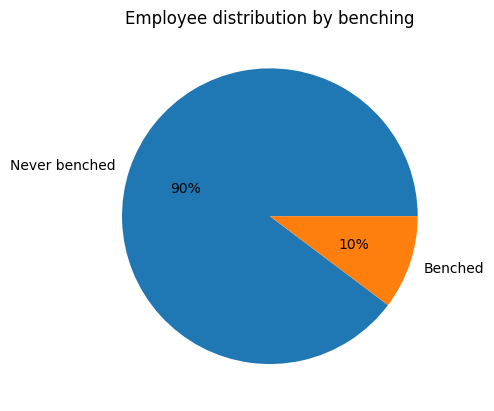

In [51]:
# Benched rate = (benched employees / total employees) * 100

benching_rate = (clean_employee_df["benched_status"]=="Benched").sum().item() / len(clean_employee_df) * 100

print(f"{benching_rate:.0f}%")

benched_status_count = fn_value_count(clean_employee_df,"benched_status")

plt.pie(x=benched_status_count.values,labels=benched_status_count.index,autopct="%1.0f%%")
plt.title("Employee distribution by benching")
plt.show()

14) Does the benched share differ by payment tier?

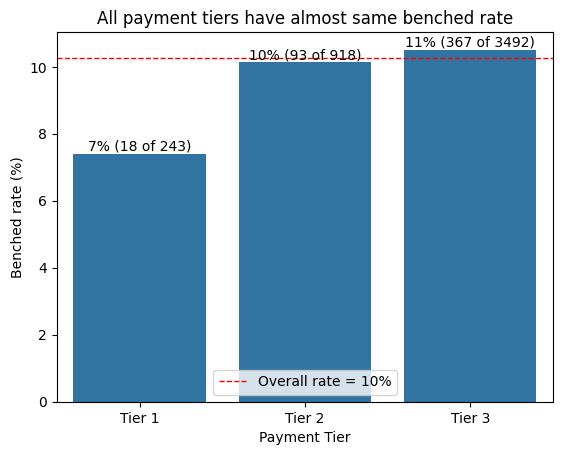

In [52]:
# Benched rate by payment tier

benching_by_payment_tier = (pd.crosstab(index=clean_employee_df['payment_tier'],columns=clean_employee_df['benched_status'],margins=True,margins_name="Total")).drop(labels="Total")

benching_by_payment_tier["Rate"] = (benching_by_payment_tier["Benched"] / benching_by_payment_tier["Total"]) * 100

benching_by_payment_tier = benching_by_payment_tier.sort_index(ascending=True)

payment_tier_with_highest_benched_rate, highest_benched_rate_by_payment_tier = (benching_by_payment_tier["Rate"].idxmax(), benching_by_payment_tier["Rate"].max())

graph = sns.barplot(data=benching_by_payment_tier,x=benching_by_payment_tier.index,y=benching_by_payment_tier["Rate"])

for container in graph.containers:
  labels = [f"{benching_by_payment_tier["Rate"].loc[tier]:.0f}% ({benching_by_payment_tier["Benched"].loc[tier]} of {benching_by_payment_tier["Total"].loc[tier]})" for tier in benching_by_payment_tier.index]
  graph.bar_label(container,labels=labels)


plt.xlabel("Payment Tier")
plt.ylabel("Benched rate (%)")
plt.title(f"All payment tiers have almost same benched rate")
graph.axhline(y=benching_rate, color='red', linestyle='--', linewidth=1.0, label=f"Overall rate = {benching_rate:.0f}%")
graph.legend()
plt.show()

15) Does the benched share differ by experience level?

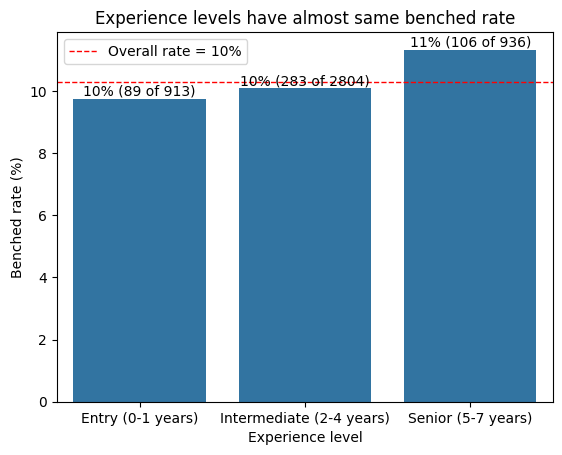

In [53]:
# Benched rate by experience level

benching_by_experience_level = (pd.crosstab(index=clean_employee_df['experience_level'],columns=clean_employee_df['benched_status'],margins=True,margins_name="Total")).drop(labels="Total")

benching_by_experience_level["Rate"] = (benching_by_experience_level["Benched"] / benching_by_experience_level["Total"]) * 100

benching_by_experience_level = benching_by_experience_level.sort_index(ascending=True)

experience_level_with_highest_benched_rate, highest_benched_rate_by_experience_level = (benching_by_experience_level["Rate"].idxmax(), benching_by_experience_level["Rate"].max())

graph = sns.barplot(data=benching_by_experience_level,x=benching_by_experience_level.index,y=benching_by_experience_level["Rate"])

for container in graph.containers:
  labels = [f"{benching_by_experience_level["Rate"].loc[level]:.0f}% ({benching_by_experience_level["Benched"].loc[level]} of {benching_by_experience_level["Total"].loc[level]})" for level in benching_by_experience_level.index]
  graph.bar_label(container,labels=labels)


plt.xlabel("Experience level")
plt.ylabel("Benched rate (%)")
plt.title(f"Experience levels have almost same benched rate")
graph.axhline(y=benching_rate, color='red', linestyle='--', linewidth=1.0, label=f"Overall rate = {benching_rate:.0f}%")
graph.legend()
plt.show()

16) Are other groups (gender, city, education, age) benched more or less often?

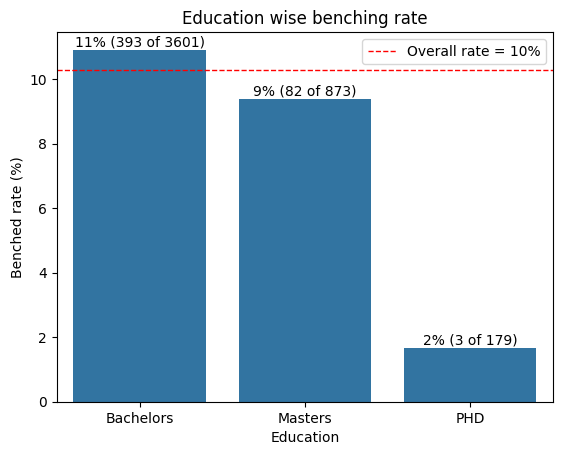

In [54]:
# Benched rate by education

benching_by_education = (pd.crosstab(index=clean_employee_df['education'],columns=clean_employee_df['benched_status'],margins=True,margins_name="Total")).drop(labels="Total")

benching_by_education["Rate"] = (benching_by_education["Benched"] / benching_by_education["Total"]) * 100

benching_by_education = benching_by_education.sort_values(by="Rate",ascending=False)

education_with_highest_benched_rate, highest_benched_rate_by_education = (benching_by_education["Rate"].idxmax(), benching_by_education["Rate"].max())

graph = sns.barplot(data=benching_by_education,x=benching_by_education.index,y=benching_by_education["Rate"])

for container in graph.containers:
  labels = [f"{benching_by_education["Rate"].loc[education]:.0f}% ({benching_by_education["Benched"].loc[education]} of {benching_by_education["Total"].loc[education]})" for education in benching_by_education.index]
  graph.bar_label(container,labels=labels)


plt.xlabel("Education")
plt.ylabel("Benched rate (%)")
plt.title(f"Education wise benching rate")
graph.axhline(y=benching_rate, color='red', linestyle='--', linewidth=1.0, label=f"Overall rate = {benching_rate:.0f}%")
graph.legend()
plt.show()

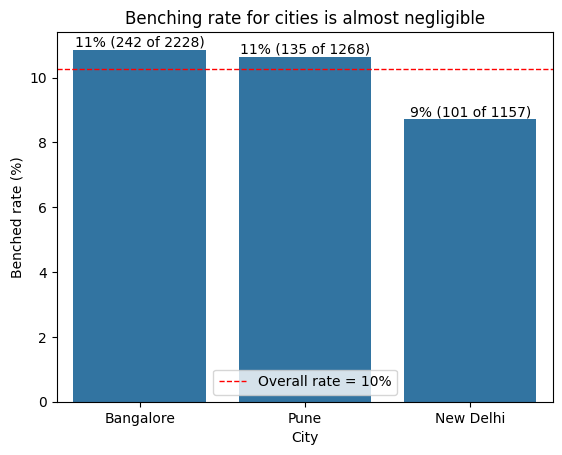

In [55]:
# Benched rate by city

benching_by_city = (pd.crosstab(index=clean_employee_df['city'],columns=clean_employee_df['benched_status'],margins=True,margins_name="Total")).drop(labels="Total")

benching_by_city["Rate"] = (benching_by_city["Benched"] / benching_by_city["Total"]) * 100

benching_by_city = benching_by_city.sort_values(by="Rate",ascending=False)

city_with_highest_benched_rate, highest_benched_rate_by_city = (benching_by_city["Rate"].idxmax(), benching_by_city["Rate"].max())

graph = sns.barplot(data=benching_by_city,x=benching_by_city.index,y=benching_by_city["Rate"])

for container in graph.containers:
  labels = [f"{benching_by_city["Rate"].loc[city]:.0f}% ({benching_by_city["Benched"].loc[city]} of {benching_by_city["Total"].loc[city]})" for city in benching_by_city.index]
  graph.bar_label(container,labels=labels)


plt.xlabel("City")
plt.ylabel("Benched rate (%)")
plt.title(f"Benching rate for cities is almost negligible")
graph.axhline(y=benching_rate, color='red', linestyle='--', linewidth=1.0, label=f"Overall rate = {benching_rate:.0f}%")
graph.legend()
plt.show()

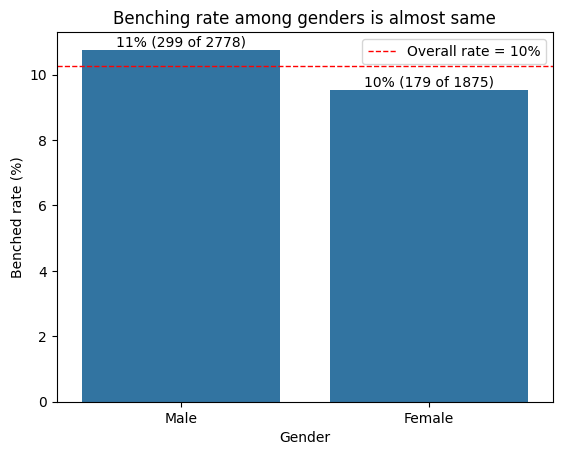

In [56]:
# Benched rate by gender

benching_by_gender = (pd.crosstab(index=clean_employee_df['gender'],columns=clean_employee_df['benched_status'],margins=True,margins_name="Total")).drop(labels="Total")

benching_by_gender["Rate"] = (benching_by_gender["Benched"] / benching_by_gender["Total"]) * 100

benching_by_gender = benching_by_gender.sort_values(by="Rate",ascending=False)

gender_with_highest_benched_rate, highest_benched_rate_by_gender = (benching_by_gender["Rate"].idxmax(), benching_by_gender["Rate"].max())

graph = sns.barplot(data=benching_by_gender,x=benching_by_gender.index,y=benching_by_gender["Rate"])

for container in graph.containers:
  labels = [f"{benching_by_gender["Rate"].loc[gender]:.0f}% ({benching_by_gender["Benched"].loc[gender]} of {benching_by_gender["Total"].loc[gender]})" for gender in benching_by_gender.index]
  graph.bar_label(container,labels=labels)


plt.xlabel("Gender")
plt.ylabel("Benched rate (%)")
plt.title(f"Benching rate among genders is almost same")
graph.axhline(y=benching_rate, color='red', linestyle='--', linewidth=1.0, label=f"Overall rate = {benching_rate:.0f}%")
graph.legend()
plt.show()

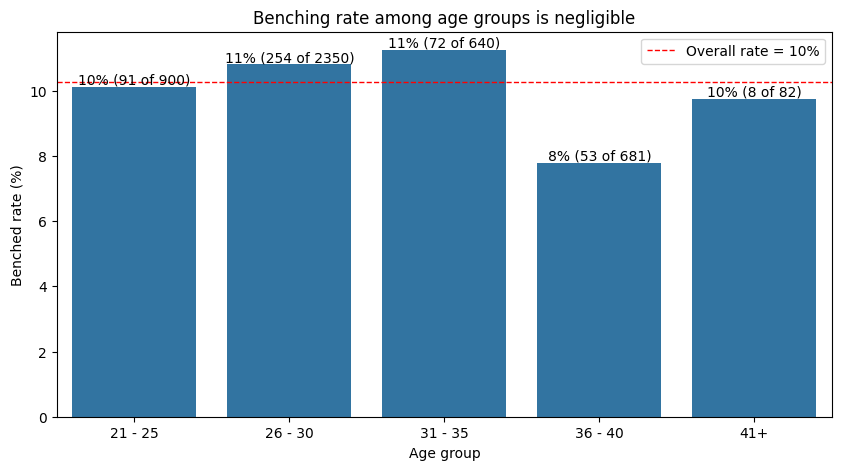

In [57]:
# Benched rate by age group

benching_by_age_group = (pd.crosstab(index=clean_employee_df['age_group'],columns=clean_employee_df['benched_status'],margins=True,margins_name="Total")).drop(labels="Total")

benching_by_age_group["Rate"] = (benching_by_age_group["Benched"] / benching_by_age_group["Total"]) * 100

benching_by_age_group = benching_by_age_group.sort_index(ascending=True)

age_group_with_highest_benched_rate, highest_benched_rate_by_age_group = (benching_by_age_group["Rate"].idxmax(), benching_by_age_group["Rate"].max())

plt.figure(figsize=(10,5))

graph = sns.barplot(data=benching_by_age_group,x=benching_by_age_group.index,y=benching_by_age_group["Rate"])

for container in graph.containers:
  labels = [f"{benching_by_age_group["Rate"].loc[age_group]:.0f}% ({benching_by_age_group["Benched"].loc[age_group]} of {benching_by_age_group["Total"].loc[age_group]})" for age_group in benching_by_age_group.index]
  graph.bar_label(container,labels=labels)


plt.xlabel("Age group")
plt.ylabel("Benched rate (%)")
plt.title(f"Benching rate among age groups is negligible")
graph.axhline(y=benching_rate, color='red', linestyle='--', linewidth=1.0, label=f"Overall rate = {benching_rate:.0f}%")
graph.legend()
plt.show()